EMAIL SPAM DATASET

Class Distribution:
is_spam
1    1760
0     240
Name: count, dtype: int64

Spam Rate:
88.0
Saved: outputs/spam_distribution.png


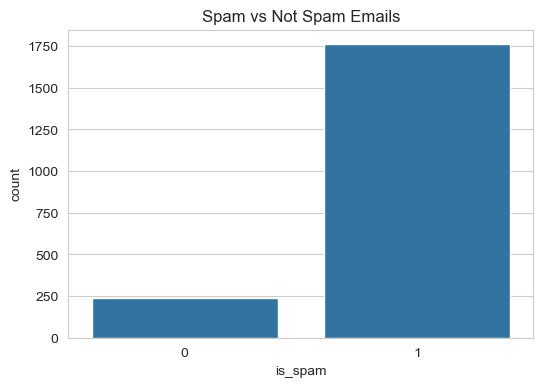

Saved: outputs/feature_distributions.png


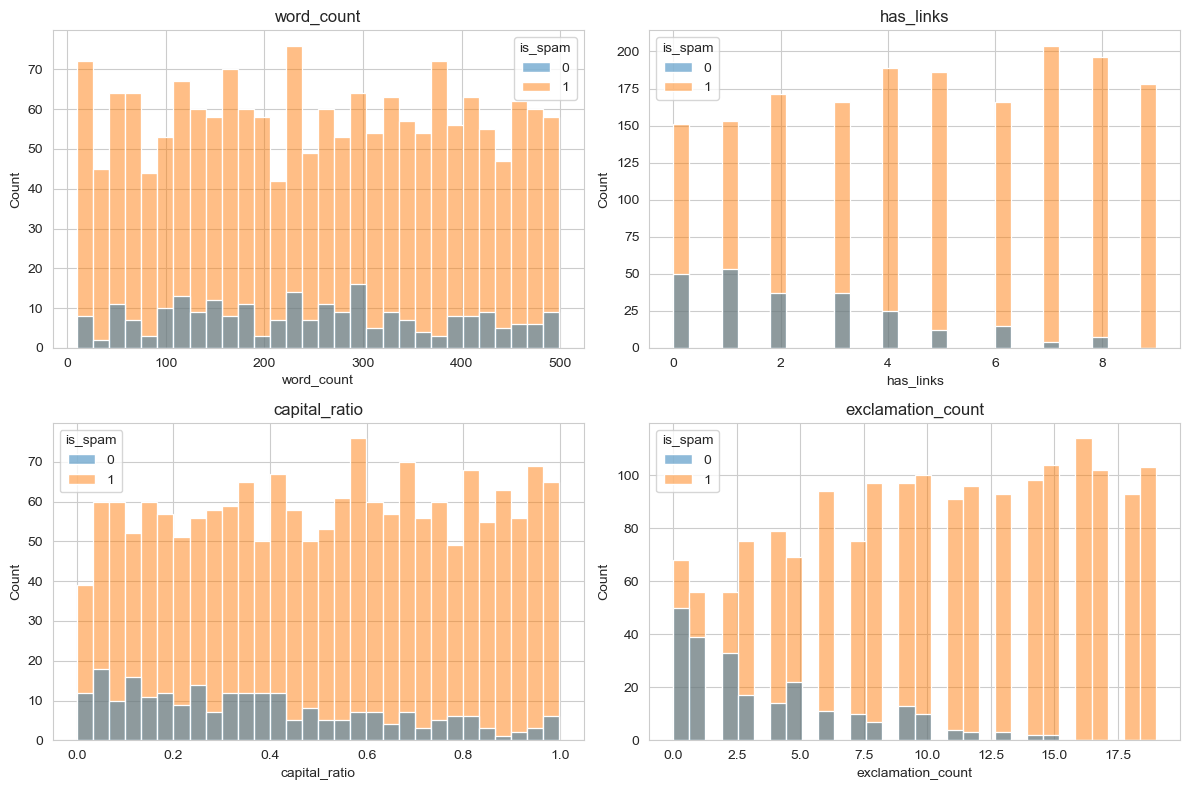


✅ Model trained successfully!

MODEL PERFORMANCE
              precision    recall  f1-score   support

    Not Spam       0.81      0.71      0.76        48
        Spam       0.96      0.98      0.97       352

    accuracy                           0.94       400
   macro avg       0.89      0.84      0.86       400
weighted avg       0.94      0.94      0.94       400

Saved: outputs/confusion_matrix.png


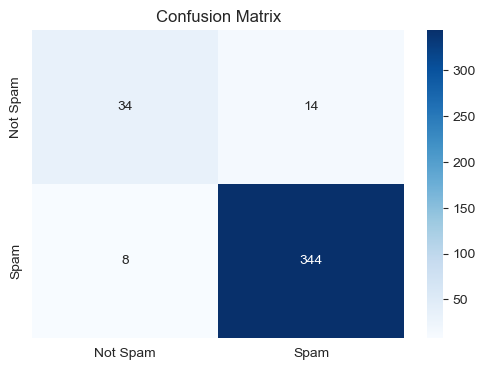


Feature Importance:

exclamation_count    3.167 ↑ Spam Risk
has_links            2.592 ↑ Spam Risk
capital_ratio        1.709 ↑ Spam Risk
has_attachments      0.080 ↑ Spam Risk
word_count           0.069 ↑ Spam Risk
known_sender         -3.078 ↓ Safe
Saved: outputs/feature_importance.png


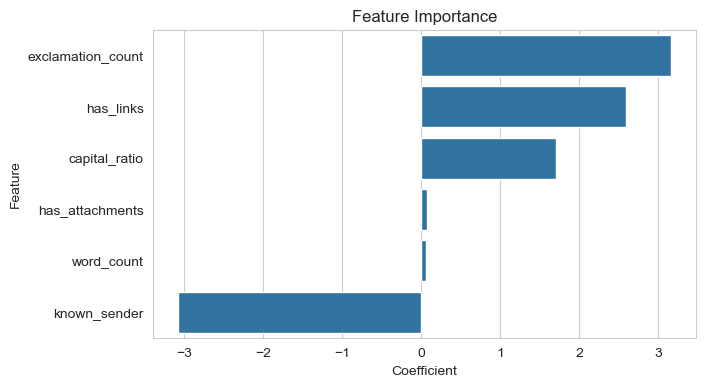


📁 Dataset saved successfully!


In [1]:
# =============================================
# Email Spam Detection — Gmail Style (FULL PROJECT)
# =============================================

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
np.random.seed(42)

# =============================================
# AUTO SAVE FUNCTION (ADD ONCE)
# =============================================

os.makedirs("outputs", exist_ok=True)

def save_plot(name):
    path = f"outputs/{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved: {path}")

# =============================================
# CREATE DATASET
# =============================================

n = 2000

df = pd.DataFrame({

    "word_count": np.random.randint(10, 500, n),

    "has_links": np.random.randint(0, 10, n),

    "has_attachments": np.random.randint(0, 3, n),

    "capital_ratio": np.random.uniform(0, 1, n),

    "exclamation_count": np.random.randint(0, 20, n),

    "known_sender": np.random.randint(0, 2, n),
})

# =============================================
# SPAM LOGIC
# =============================================

spam_score = (

    df["has_links"] * 0.3 +

    df["capital_ratio"] * 2.0 +

    df["exclamation_count"] * 0.2 +

    df["known_sender"] * -2.0 +

    np.random.normal(0, 0.5, n)
)

df["is_spam"] = (spam_score > 1.0).astype(int)

# =============================================
# DATA INFO
# =============================================

print("=" * 50)
print("EMAIL SPAM DATASET")
print("=" * 50)

print("\nClass Distribution:")
print(df["is_spam"].value_counts())

print("\nSpam Rate:")
print(df["is_spam"].mean() * 100)

# =============================================
# VISUALIZATION 1 — CLASS DISTRIBUTION
# =============================================

plt.figure(figsize=(6,4))

sns.countplot(data=df, x="is_spam")

plt.title("Spam vs Not Spam Emails")

save_plot("spam_distribution")

plt.show()

# =============================================
# VISUALIZATION 2 — FEATURE DISTRIBUTIONS
# =============================================

features = [
    "word_count",
    "has_links",
    "capital_ratio",
    "exclamation_count"
]

fig, axes = plt.subplots(2, 2, figsize=(12,8))

for idx, feature in enumerate(features):

    row = idx // 2
    col = idx % 2

    sns.histplot(
        data=df,
        x=feature,
        hue="is_spam",
        bins=30,
        ax=axes[row, col]
    )

    axes[row, col].set_title(feature)

plt.tight_layout()

save_plot("feature_distributions")

plt.show()

# =============================================
# FEATURES & TARGET
# =============================================

X = df.drop("is_spam", axis=1)
y = df["is_spam"]

# =============================================
# TRAIN TEST SPLIT
# =============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =============================================
# SCALING
# =============================================

scaler = StandardScaler()

X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# =============================================
# MODEL TRAINING
# =============================================

model = LogisticRegression(random_state=42)

model.fit(X_train_sc, y_train)

print("\n✅ Model trained successfully!")

# =============================================
# PREDICTIONS
# =============================================

y_pred = model.predict(X_test_sc)

# =============================================
# EVALUATION
# =============================================

print("\n" + "=" * 50)
print("MODEL PERFORMANCE")
print("=" * 50)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Spam", "Spam"]
))

# =============================================
# CONFUSION MATRIX
# =============================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("Confusion Matrix")

save_plot("confusion_matrix")

plt.show()

# =============================================
# FEATURE IMPORTANCE
# =============================================

coef_df = pd.DataFrame({

    "Feature": X.columns,

    "Coefficient": model.coef_[0]

}).sort_values("Coefficient", ascending=False)

print("\nFeature Importance:\n")

for _, row in coef_df.iterrows():

    direction = "↑ Spam Risk" if row["Coefficient"] > 0 else "↓ Safe"

    print(f"{row['Feature']:<20} {row['Coefficient']:.3f} {direction}")

# =============================================
# BAR PLOT FEATURE IMPORTANCE
# =============================================

plt.figure(figsize=(7,4))

sns.barplot(
    data=coef_df,
    x="Coefficient",
    y="Feature"
)

plt.title("Feature Importance")

save_plot("feature_importance")

plt.show()

# =============================================
# SAVE DATASET
# =============================================

df.to_csv("email_spam_dataset.csv", index=False)

print("\n📁 Dataset saved successfully!")